### Option A — dual-head TCN

A8q is frozen in `option_a_a8q.pth` (TEST **1.12 m / 4.95°**). **Restart + Run All** trains a new run (A9) into `option_a.pth` / `results.png`. It will not overwrite the A8q archive.


In [1]:
import os, random, json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

SEED = 1
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

IMU_FS = 160
WIN_SEC, EXTRACT_SEC, HOP_SEC, RTE_SEC = 1.0, 0.1, 1.0, 1.0
W = int(WIN_SEC * IMU_FS)
STRIDE = int(EXTRACT_SEC * IMU_FS)
HOP_N = int(round(HOP_SEC / EXTRACT_SEC))
BATCH_SIZE, EPOCHS, LR = 256, 80, 1e-3
LAMBDA_ROT = 1.0
VAL_FRAC, TEST_FRAC, GAP = 0.15, 0.15, HOP_N

assert os.path.exists("dataset.csv"), "run make_dataset.m first"
print("RUN_ID=A9_TCN", device, "W", W, "extract", STRIDE, "hop_n", HOP_N, "gap", GAP)


RUN_ID=A9_TCN cuda W 160 extract 16 hop_n 10 gap 10


In [2]:
COLS = [
    "accx","accy","accz","wx","wy","wz",
    "magx","magy","magz","velx","vely","velz",
    "posx","posy","posz","qw","qx","qy","qz",
]
df = pd.read_csv("dataset.csv", names=COLS)
meas = df[COLS[:12]].to_numpy(np.float32)
pos = df[["posx","posy","posz"]].to_numpy(np.float32)
quat = df[["qw","qx","qy","qz"]].to_numpy(np.float32)
print(df.shape)

(22560, 19)


In [3]:
def q_normalize(q, eps=1e-8):
    return q / (np.linalg.norm(q, axis=-1, keepdims=True) + eps)

def q_conj(q):
    o = q.copy(); o[..., 1:] *= -1; return o

def q_mul(a, b):
    aw, ax, ay, az = (a[..., k] for k in range(4))
    bw, bx, by, bz = (b[..., k] for k in range(4))
    return np.stack([
        aw*bw - ax*bx - ay*by - az*bz,
        aw*bx + ax*bw + ay*bz - az*by,
        aw*by - ax*bz + ay*bw + az*bx,
        aw*bz + ax*by - ay*bx + az*bw,
    ], axis=-1)

def q_delta(q0, q1):
    return q_normalize(q_mul(q_conj(q_normalize(q0)), q_normalize(q1)))

def quat_to_rotvec(q):
    q = q_normalize(q)
    q = np.where(q[..., :1] < 0, -q, q)
    w = np.clip(q[..., 0], -1, 1)
    xyz = q[..., 1:]
    n = np.linalg.norm(xyz, axis=-1, keepdims=True)
    angle = 2 * np.arccos(w)
    axis = xyz / np.clip(n, 1e-8, None)
    return (axis * angle[..., None]).astype(np.float32)

def rotvec_to_quat(v, eps=1e-8):
    angle = np.linalg.norm(v, axis=-1, keepdims=True)
    axis = v / np.clip(angle, eps, None)
    half = 0.5 * angle
    return np.concatenate([np.cos(half), axis * np.sin(half)], -1).astype(np.float32)

def q_ang_deg(qa, qb):
    d = np.clip(np.abs((q_normalize(qa) * q_normalize(qb)).sum(-1)), -1, 1)
    return np.degrees(2 * np.arccos(d))

In [4]:
quat = q_normalize(quat)
ends = np.arange(W - 1, len(df), STRIDE)
X = np.stack([meas[t - W + 1:t + 1].T for t in ends], 0)
v_gps = meas[ends, 9:12]
vel = (pos[ends] - pos[ends - (W - 1)]) / WIN_SEC
drot = quat_to_rotvec(q_delta(quat[np.maximum(ends - STRIDE, 0)], quat[ends]))
dv = vel - v_gps
Y = np.concatenate([dv, drot], 1)
pos_end, q_end = pos[ends], quat[ends]
print(X.shape, Y.shape, "vel std", vel.std(0), "dv std", dv.std(0), "drot std rad", drot.std(0))

(1401, 12, 160) (1401, 6) vel std [0.7168908  0.6722952  0.70806617] dv std [0.34355506 0.33659002 0.26131845] drot std rad [0.01466625 0.00900928 0.01120513]


In [5]:
N = len(X)
n_test, n_val = int(N * TEST_FRAC), int(N * VAL_FRAC)
n_train = N - n_val - n_test - 2 * GAP
tr = slice(0, n_train)
va = slice(n_train + GAP, n_train + GAP + n_val)
te = slice(n_train + GAP + n_val + GAP, N)
X_tr, Y_tr = X[tr], Y[tr]
X_va, Y_va = X[va], Y[va]
X_te, Y_te = X[te], Y[te]
pos_tr = pos_end[tr]
pos_va, q_va = pos_end[va], q_end[va]
pos_te, q_te = pos_end[te], q_end[te]
v_gps_tr, v_gps_va, v_gps_te = v_gps[tr], v_gps[va], v_gps[te]
t_end = ends / IMU_FS
print(len(X_tr), len(X_va), len(X_te), "1s hops", (len(X_tr) + HOP_N - 1) // HOP_N, (len(X_va) + HOP_N - 1) // HOP_N, (len(X_te) + HOP_N - 1) // HOP_N)
print(
    f"TRAIN {t_end[tr][0]:.1f}–{t_end[tr][-1]:.1f}s  "
    f"VAL {t_end[va][0]:.1f}–{t_end[va][-1]:.1f}s  "
    f"TEST {t_end[te][0]:.1f}–{t_end[te][-1]:.1f}s"
)

961 210 210 1s hops 97 21 21
TRAIN 1.0–97.0s  VAL 98.1–119.0s  TEST 120.1–141.0s


In [6]:
feat_mean, feat_std = X_tr.mean((0, 2)), X_tr.std((0, 2)) + 1e-8
y_mean, y_std = Y_tr.mean(0), Y_tr.std(0) + 1e-8
y_mean_t = torch.tensor(y_mean)
y_std_t = torch.tensor(y_std)

def nX(a):
    return (a - feat_mean[None, :, None]) / feat_std[None, :, None]

def nY(a):
    return (a - y_mean) / y_std

def denorm_t(p):
    return p * y_std_t.to(p.device) + y_mean_t.to(p.device)

X_tr_n, X_va_n, X_te_n = nX(X_tr), nX(X_va), nX(X_te)
Y_tr_n, Y_va_n, Y_te_n = nY(Y_tr), nY(Y_va), nY(Y_te)

In [7]:
class IncDS(Dataset):
    def __init__(self, x, y):
        self.x = torch.tensor(x, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self):
        return len(self.x)
    def __getitem__(self, i):
        return self.x[i], self.y[i]

train_loader = DataLoader(IncDS(X_tr_n, Y_tr_n), BATCH_SIZE, shuffle=True)
val_loader = DataLoader(IncDS(X_va_n, Y_va_n), BATCH_SIZE)
test_loader = DataLoader(IncDS(X_te_n, Y_te_n), BATCH_SIZE)
print("train", len(train_loader.dataset), "val", len(val_loader.dataset), "test", len(test_loader.dataset))

train 961 val 210 test 210


In [8]:
class TcnBlock(nn.Module):
    def __init__(self, ch, k, d):
        super().__init__()
        pad = (k - 1) * d // 2
        self.f = nn.Sequential(
            nn.Conv1d(ch, ch, k, padding=pad, dilation=d),
            nn.ReLU(),
            nn.Conv1d(ch, ch, k, padding=pad, dilation=d),
        )
        self.act = nn.ReLU()
    def forward(self, x):
        return self.act(x + self.f(x))

class IncModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = nn.Conv1d(12, 64, 5, padding=2)
        self.tcn = nn.Sequential(
            TcnBlock(64, 5, 1),
            TcnBlock(64, 5, 2),
            TcnBlock(64, 5, 4),
            TcnBlock(64, 5, 8),
        )
        self.head_v = nn.Sequential(nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 3))
        self.head_q = nn.Sequential(nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 3))
    def forward(self, x):
        z = torch.relu(self.stem(x))
        z = self.tcn(z)
        h = torch.cat([z.mean(-1), z[:, :, -1]], 1)
        return torch.cat([self.head_v(h), self.head_q(h)], 1)

_m = IncModel()
print(_m(torch.zeros(2, 12, W)).shape, "params", sum(p.numel() for p in _m.parameters()))

torch.Size([2, 6]) params 185158


### A8q archive (frozen, no train)

Loads `option_a_a8q.pth` and prints both A8 snapshots. Does not write `results.png`.


In [9]:
def ate_rte(est, ref, hop=HOP_SEC, sec=RTE_SEC):
    ate = float(np.sqrt(((est - ref) ** 2).sum(1).mean()))
    w = max(int(round(sec / hop)), 1)
    rel = [
        np.linalg.norm((est[i + w] - est[i]) - (ref[i + w] - ref[i]))
        for i in range(0, len(est) - w, max(w // 2, 1))
    ]
    return ate, float(np.mean(rel)) if rel else float("nan")

def integrate_pos(vel, pos0):
    n = len(vel)
    pos_hat = np.zeros((n, 3), np.float32)
    pos_hat[0] = pos0
    for t in range(1, n):
        pos_hat[t] = pos_hat[t - 1] + vel[t] * HOP_SEC
    return pos_hat

def integrate_q(drot, q0):
    n = len(drot)
    q_hat = np.zeros((n, 4), np.float32)
    q_hat[0] = q0
    for t in range(1, n):
        q_hat[t] = q_normalize(q_mul(q_hat[t - 1], rotvec_to_quat(drot[t])))
    return q_hat

@torch.no_grad()
def predict_inc(Xn):
    model.eval()
    out = []
    for i in range(0, len(Xn), BATCH_SIZE):
        xb = torch.tensor(Xn[i:i + BATCH_SIZE], device=device)
        p = model(xb).cpu() * y_std_t + y_mean_t
        out.append(p.numpy())
    return np.concatenate(out)

@torch.no_grad()
def eval_inc(model, loader):
    model.eval()
    se_v, se_r, n = 0.0, 0.0, 0
    for xb, yb in loader:
        p = denorm_t(model(xb.to(device))).cpu()
        t = denorm_t(yb)
        se_v += ((p[:, :3] - t[:, :3]) ** 2).sum().item()
        se_r += ((p[:, 3:] - t[:, 3:]) ** 2).sum().item()
        n += len(p)
    model.train()
    return (se_v / (n * 3)) ** 0.5, np.degrees((se_r / (n * 3)) ** 0.5)

@torch.no_grad()
def split_ate(Xn, vg, pos_ref, q_ref):
    inc = predict_inc(Xn)
    v = vg + inc[:, :3]
    ph = integrate_pos(v[::HOP_N], pos_ref[::HOP_N][0])
    qh = integrate_q(inc[:, 3:], q_ref[0])
    ate, _ = ate_rte(ph, pos_ref[::HOP_N])
    return ate, float(q_ang_deg(qh, q_ref).mean())

def score_state(state, name):
    model.load_state_dict(state)
    inc = predict_inc(X_te_n)
    v_hat = v_gps_te + inc[:, :3]
    pos_1s = pos_te[::HOP_N]
    pos_h = integrate_pos(v_hat[::HOP_N], pos_1s[0])
    q_h = integrate_q(inc[:, 3:], q_te[0])
    ate, rte = ate_rte(pos_h, pos_1s)
    quat = float(q_ang_deg(q_h, q_te).mean())
    print(f"{name:<12} ATE {ate:.3f} m  RTE {rte:.3f} m  quat {quat:.2f} deg")
    return {"ate_m": ate, "rte_m": rte, "quat_mean_deg": quat}

ck = torch.load("option_a_a8q.pth", map_location=device)
print("A8q archive", ck.get("run_id"), "file=option_a_a8q.pth")
model = IncModel().to(device)
score_state(ck["state_ate"], "A8 ATE ckpt")
score_state(ck["state_q"], "A8q quat ckpt")
print("archive only — not writing results.png")


A8q archive A8_TCN file=option_a_a8q.pth


A8 ATE ckpt  ATE 0.926 m  RTE 0.323 m  quat 14.28 deg
A8q quat ckpt ATE 1.119 m  RTE 0.312 m  quat 4.95 deg
archive only — not writing results.png


  0  train 7.7061  val ATE 2.285 m  δv 0.3660 m/s  Δθ 0.668 deg  quat 15.21
  5  train 3.3765  val ATE 2.201 m  δv 0.3304 m/s  Δθ 0.290 deg  quat 19.29
 10  train 2.1872  val ATE 2.428 m  δv 0.3208 m/s  Δθ 0.194 deg  quat 13.29
 15  train 1.6309  val ATE 2.167 m  δv 0.3148 m/s  Δθ 0.167 deg  quat 10.88
 20  train 1.2780  val ATE 2.028 m  δv 0.3080 m/s  Δθ 0.157 deg  quat 9.87
 25  train 1.0804  val ATE 1.500 m  δv 0.2991 m/s  Δθ 0.148 deg  quat 7.86
 30  train 0.9417  val ATE 1.428 m  δv 0.2994 m/s  Δθ 0.146 deg  quat 3.97
 35  train 0.8552  val ATE 1.650 m  δv 0.2992 m/s  Δθ 0.144 deg  quat 4.49
 40  train 0.7819  val ATE 1.323 m  δv 0.2982 m/s  Δθ 0.140 deg  quat 3.40
 45  train 0.7308  val ATE 1.516 m  δv 0.2986 m/s  Δθ 0.140 deg  quat 4.68
 50  train 0.6664  val ATE 1.415 m  δv 0.2994 m/s  Δθ 0.140 deg  quat 5.26
 55  train 0.6049  val ATE 1.472 m  δv 0.3006 m/s  Δθ 0.139 deg  quat 5.14
 60  train 0.5486  val ATE 1.407 m  δv 0.2984 m/s  Δθ 0.135 deg  quat 3.36
 65  train 0.5059  va

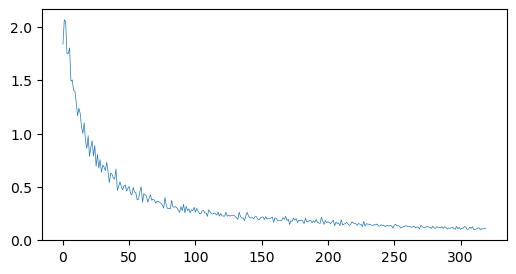

val best-ATE (1.2064622640609741, 2.997328042984009) best-quat (1.375009536743164, 2.248687267303467) official quat
test Δ (0.2183192642321478, 0.10659519610982059)


In [10]:
def snap():
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

model = IncModel().to(device)
opt = torch.optim.Adam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=8, factor=0.5)
losses = []
best_ate, best_q = float("inf"), float("inf")
state_ate, state_q = None, None
rec_ate, rec_q = None, None

for e in range(EPOCHS):
    model.train()
    run = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        pred = model(xb)
        loss = nn.functional.mse_loss(pred[:, :3], yb[:, :3]) + LAMBDA_ROT * nn.functional.mse_loss(pred[:, 3:], yb[:, 3:])
        opt.zero_grad()
        loss.backward()
        opt.step()
        run += loss.item()
        losses.append(loss.item())
    dv, dr = eval_inc(model, val_loader)
    ate_v, qv = split_ate(X_va_n, v_gps_va, pos_va, q_va)
    sched.step(ate_v + qv / 30)
    if ate_v < best_ate:
        best_ate, state_ate, rec_ate = ate_v, snap(), (ate_v, qv)
    if qv < best_q:
        best_q, state_q, rec_q = qv, snap(), (ate_v, qv)
    if e % 5 == 0 or e == EPOCHS - 1:
        print(f"{e:3d}  train {run:.4f}  val ATE {ate_v:.3f} m  δv {dv:.4f} m/s  Δθ {dr:.3f} deg  quat {qv:.2f}")

selected = "quat"
model.load_state_dict(state_q)
plt.figure(figsize=(6, 3))
plt.plot(losses, lw=0.5)
plt.show()
print("val best-ATE", rec_ate, "best-quat", rec_q, "official", selected)
print("test Δ", eval_inc(model, test_loader))


In [11]:
inc = predict_inc(X_te_n)
dv_hat, drot_hat = inc[:, :3], inc[:, 3:]
v_hat = v_gps_te + dv_hat
v_gt = Y_te[:, :3] + v_gps_te
pos_te_1s, q_te_1s = pos_te[::HOP_N], q_te[::HOP_N]
v_hat_1s, v_gt_1s = v_hat[::HOP_N], v_gt[::HOP_N]
v_gps_1s = v_gps_te[::HOP_N]
pos_hat = integrate_pos(v_hat_1s, pos_te_1s[0])
q_hat = integrate_q(drot_hat, q_te[0])
pos_gps = integrate_pos(v_gps_1s, pos_te_1s[0])

ate_a, rte_a = ate_rte(pos_hat, pos_te_1s)
ate_g, rte_g = ate_rte(pos_gps, pos_te_1s)
quat_a = float(q_ang_deg(q_hat, q_te).mean())
quat_a_1s = float(q_ang_deg(q_hat[::HOP_N], q_te_1s).mean())
vel_rmse = float(np.sqrt(((v_hat_1s - v_gt_1s) ** 2).mean()))
vel_bias = (v_hat_1s - v_gt_1s).mean(0)
print(f"A       ATE {ate_a:.3f} m  RTE {rte_a:.3f} m  quat 0.1s {quat_a:.2f} deg  quat 1s {quat_a_1s:.2f} deg")
print(f"GPS vel ATE {ate_g:.3f} m  RTE {rte_g:.3f} m")
print(f"vel RMSE {vel_rmse:.4f} m/s  bias {vel_bias}  |bias| {np.linalg.norm(vel_bias):.4f}")


A       ATE 1.533 m  RTE 0.331 m  quat 0.1s 5.03 deg  quat 1s 4.81 deg
GPS vel ATE 1.103 m  RTE 0.451 m
vel RMSE 0.2344 m/s  bias [-0.07426311 -0.01184561 -0.07029898]  |bias| 0.1029


In [12]:
diag = np.loadtxt("filterstate.csv", delimiter=",")
ekf_pos = diag[:, 1:4].astype(np.float32)
ekf_q = q_normalize(diag[:, 4:8].astype(np.float32))
ends_te = ends[te]
pos_ekf = ekf_pos[ends_te[::HOP_N]]
q_ekf = q_normalize(ekf_q[ends_te])
ate_e, rte_e = ate_rte(pos_ekf, pos_te_1s)
quat_e = float(q_ang_deg(q_ekf, q_te).mean())
print(f"EKF ATE {ate_e:.3f} m  RTE {rte_e:.3f} m  quat {quat_e:.2f} deg")
print(f"{'method':<16} {'ATE':>8} {'RTE':>8}")
print(f"{'A9 TCN '+selected:<16} {ate_a:8.3f} {rte_a:8.3f}")
print(f"{'GPS vel int':<16} {ate_g:8.3f} {rte_g:8.3f}")
print(f"{'insfilterMARG':<16} {ate_e:8.3f} {rte_e:8.3f}")

def slice_ate(est, ref, sl):
    e = est[sl] - ref[sl]
    return {
        "ate_m": float(np.sqrt((e ** 2).sum(1).mean())),
        "mean_m": float(np.linalg.norm(e, axis=1).mean()),
        "rmse_xyz_m": np.sqrt((e ** 2).mean(0)).astype(float).tolist(),
    }

n_te = len(pos_te_1s)
first = slice(0, min(11, n_te))
last = slice(max(0, n_te - 11), n_te)
seg_a = {"first_10s": slice_ate(pos_hat, pos_te_1s, first), "last_10s": slice_ate(pos_hat, pos_te_1s, last)}
seg_e = {"first_10s": slice_ate(pos_ekf, pos_te_1s, first), "last_10s": slice_ate(pos_ekf, pos_te_1s, last)}
print("A  first10", seg_a["first_10s"], "last10", seg_a["last_10s"])
print("EKF first10", seg_e["first_10s"], "last10", seg_e["last_10s"])


EKF ATE 0.775 m  RTE 0.201 m  quat 7.46 deg
method                ATE      RTE
A9 TCN quat         1.533    0.331
GPS vel int         1.103    0.451
insfilterMARG       0.775    0.201
A  first10 {'ate_m': 1.3113172054290771, 'mean_m': 1.1497395038604736, 'rmse_xyz_m': [0.3174603581428528, 0.5613762736320496, 1.1417654752731323]} last10 {'ate_m': 1.7472916841506958, 'mean_m': 1.7384815216064453, 'rmse_xyz_m': [0.4654850959777832, 0.34970521926879883, 1.6474398374557495]}
EKF first10 {'ate_m': 0.7258488535881042, 'mean_m': 0.7066875100135803, 'rmse_xyz_m': [0.4250543415546417, 0.5270529985427856, 0.2615348994731903]} last10 {'ate_m': 0.8039908409118652, 'mean_m': 0.7863655686378479, 'rmse_xyz_m': [0.5136095881462097, 0.15268193185329437, 0.5994119048118591]}


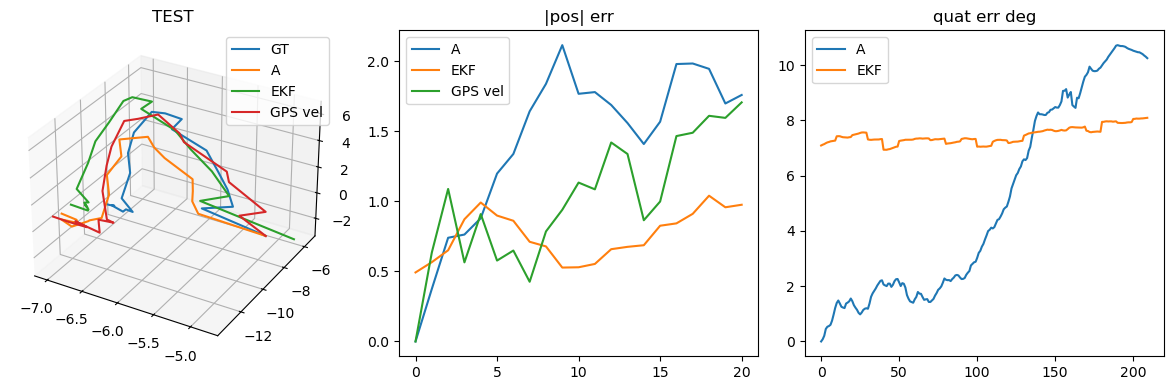

{
  "run_id": "A9_TCN",
  "arch": "dual_head_tcn",
  "selected_ckpt": "quat",
  "val_best_ate": {
    "ate_m": 1.2064622640609741,
    "quat_deg": 2.997328042984009
  },
  "val_best_quat": {
    "ate_m": 1.375009536743164,
    "quat_deg": 2.248687267303467
  },
  "device": "cuda",
  "W": 160,
  "stride": 16,
  "extract_sec": 0.1,
  "hop_sec": 1.0,
  "gap": 10,
  "n_train": 961,
  "n_val": 210,
  "n_test_dense": 210,
  "n_test": 21,
  "test_vel_rmse_m_s": 0.23443347215652466,
  "test_vel_bias_m_s": [
    -0.07426311075687408,
    -0.011845612898468971,
    -0.07029897719621658
  ],
  "test_vel_bias_norm_m_s": 0.1029430627822876,
  "test_dtheta_rmse_deg": 0.10659519610982059,
  "A": {
    "ate_m": 1.5334218740463257,
    "rte_m": 0.330579936504364,
    "quat_mean_deg": 5.027093887329102,
    "quat_mean_deg_1s": 4.813783168792725,
    "first_10s": {
      "ate_m": 1.3113172054290771,
      "mean_m": 1.1497395038604736,
      "rmse_xyz_m": [
        0.3174603581428528,
        0.5613762736

In [13]:
fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(131, projection="3d")
ax.plot(*pos_te_1s.T, label="GT")
ax.plot(*pos_hat.T, label="A")
ax.plot(*pos_ekf.T, label="EKF")
ax.plot(*pos_gps.T, label="GPS vel")
ax.legend()
ax.set_title("TEST")
ax2 = fig.add_subplot(132)
t1 = np.arange(len(pos_te_1s))
ax2.plot(t1, np.linalg.norm(pos_hat - pos_te_1s, axis=1), label="A")
ax2.plot(t1, np.linalg.norm(pos_ekf - pos_te_1s, axis=1), label="EKF")
ax2.plot(t1, np.linalg.norm(pos_gps - pos_te_1s, axis=1), label="GPS vel")
ax2.legend()
ax2.set_title("|pos| err")
ax3 = fig.add_subplot(133)
ax3.plot(q_ang_deg(q_hat, q_te), label="A")
ax3.plot(q_ang_deg(q_ekf, q_te), label="EKF")
ax3.legend()
ax3.set_title("quat err deg")
plt.tight_layout()
plt.show()

dp, dr = eval_inc(model, test_loader)
results = {
    "run_id": "A9_TCN",
    "arch": "dual_head_tcn",
    "selected_ckpt": selected,
    "val_best_ate": {"ate_m": rec_ate[0], "quat_deg": rec_ate[1]},
    "val_best_quat": {"ate_m": rec_q[0], "quat_deg": rec_q[1]},
    "device": device,
    "W": W,
    "stride": STRIDE,
    "extract_sec": EXTRACT_SEC,
    "hop_sec": HOP_SEC,
    "gap": GAP,
    "n_train": int(len(X_tr)),
    "n_val": int(len(X_va)),
    "n_test_dense": int(len(X_te)),
    "n_test": int(len(pos_te_1s)),
    "test_vel_rmse_m_s": vel_rmse,
    "test_vel_bias_m_s": vel_bias.astype(float).tolist(),
    "test_vel_bias_norm_m_s": float(np.linalg.norm(vel_bias)),
    "test_dtheta_rmse_deg": float(dr),
    "A": {
        "ate_m": float(ate_a),
        "rte_m": float(rte_a),
        "quat_mean_deg": quat_a,
        "quat_mean_deg_1s": quat_a_1s,
        **seg_a,
    },
    "GPS_vel": {"ate_m": float(ate_g), "rte_m": float(rte_g)},
    "EKF": {
        "ate_m": float(ate_e),
        "rte_m": float(rte_e),
        "quat_mean_deg": quat_e,
        **seg_e,
    },
}
with open("results.json", "w") as f:
    json.dump(results, f, indent=2)
np.savez(
    "results.npz",
    pos_te=pos_te_1s, pos_hat=pos_hat, pos_ekf=pos_ekf, pos_gps=pos_gps,
    q_te=q_te, q_hat=q_hat, q_ekf=q_ekf,
    v_hat=v_hat_1s, v_gt=v_gt_1s, v_gps=v_gps_1s,
)
fig.savefig("results.png", dpi=120)
torch.save(
    {
        "run_id": "A9_TCN",
        "selected_ckpt": selected,
        "extract_sec": EXTRACT_SEC,
        "state": model.state_dict(),
        "state_ate": state_ate,
        "state_q": state_q,
        "feat_mean": feat_mean,
        "feat_std": feat_std,
        "y_mean": y_mean,
        "y_std": y_std,
        "W": W,
        "stride": STRIDE,
        "hop_sec": HOP_SEC,
    },
    "option_a.pth",
)
print(json.dumps(results, indent=2))
print("wrote option_a.pth (A9). A8q archive untouched: option_a_a8q.pth")
